# Imports

In [1]:
import time
import requests
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from itertools import product
from collections import deque

# Configuration

In [2]:
# Account
INITIAL_BALANCE = 10_000
RISK_PER_TRADE = 0.10
LEVERAGE = 1.0

# Costs/Fees
TAKER_FEE_RATE = 0.0010
SLIPPAGE_RATE = 0.0005
ONE_WAY_COST = TAKER_FEE_RATE + SLIPPAGE_RATE

# Data
BASE_URL = "https://data-api.binance.vision"
SYMBOL = "BTCUSDT"
BAR_SIZE = "1h"

# Data Window
START = "2015-07-01 00:00:00"
END   = "2026-08-01 00:00:00"

# Parameters
HORIZON = 44
THRESHOLD_MULTIPLIER = 0.088
ALLOW_SHORTS = True
SCALER_ROWS = 400

# Model Parameters
LR = 0.002675
MODEL_L2 = 3.75
HIDDEN_SIZE = 20

# Parameters Study Grid
HORIZON_GRID = [43, 44, 45]
THRESHOLD_MULTIPLIER_GRID = [0.066, 0.088, 0.01]

# Hyperparameters Study Grid
LR_GRID = [0.002650, 0.002675, 0.002700]
MODEL_L2_GRID = [3.5, 3.75, 4.0]
HIDDEN_SIZE_GRID = [19, 20, 21]
#44	0.088	0.002675	3.75	20

# Data Loader

In [3]:
def load_data(symbol, start, end, interval, limit=1000):
    start_ms = int(pd.Timestamp(start, tz="UTC").timestamp() * 1000)
    end_ms = int(pd.Timestamp(end, tz="UTC").timestamp() * 1000)

    all_rows = []
    current_start = start_ms

    while current_start < end_ms:
        url = f"{BASE_URL}/api/v3/klines"
        params = {
            "symbol": symbol,
            "interval": interval,
            "startTime": current_start,
            "endTime": end_ms,
            "limit": limit,
        }

        r = requests.get(url, params=params, timeout=30)
        r.raise_for_status()
        rows = r.json()

        if not rows:
            break

        all_rows.extend(rows)

        last_open_time = rows[-1][0]
        next_start = last_open_time + 1

        if next_start <= current_start:
            break

        current_start = next_start
        time.sleep(0.05)

    if not all_rows:
        raise ValueError("No data returned from Binance.")

    cols = [
        "open_time", "open", "high", "low", "close", "volume",
        "close_time", "quote_asset_volume", "number_of_trades",
        "taker_buy_base_asset_volume", "taker_buy_quote_asset_volume", "ignore"
    ]

    df = pd.DataFrame(all_rows, columns=cols)
    df["open_time"] = pd.to_datetime(df["open_time"], unit="ms", utc=True)
    df["close_time"] = pd.to_datetime(df["close_time"], unit="ms", utc=True)

    numeric_cols = [
        "open", "high", "low", "close", "volume",
        "quote_asset_volume", "number_of_trades",
        "taker_buy_base_asset_volume", "taker_buy_quote_asset_volume"
    ]

    for c in numeric_cols:
        df[c] = pd.to_numeric(df[c], errors="coerce")

    df = df.sort_values("open_time").drop_duplicates("open_time").reset_index(drop=True)
    df = df.set_index("open_time")

    return df

# Load Raw Data

In [4]:
raw_df = load_data(SYMBOL, START, END, BAR_SIZE)
raw_df.head()

,open,high,low,close,volume,close_time,quote_asset_volume,number_of_trades,taker_buy_base_asset_volume,taker_buy_quote_asset_volume,ignore
open_time,,,,,,,,,,,
2017-08-17 04:00:00+00:00,4261.48,4313.62,4261.32,4308.83,47.181009,2017-08-17 04:59:59.999000+00:00,202366.138393,171,35.160503,150952.477943,0
2017-08-17 05:00:00+00:00,4308.83,4328.69,4291.37,4315.32,23.234916,2017-08-17 05:59:59.999000+00:00,100304.823567,102,21.448071,92608.279728,0
2017-08-17 06:00:00+00:00,4330.29,4345.45,4309.37,4324.35,7.229691,2017-08-17 06:59:59.999000+00:00,31282.312670,36,4.802861,20795.317224,0
2017-08-17 07:00:00+00:00,4316.62,4349.99,4287.41,4349.99,4.443249,2017-08-17 07:59:59.999000+00:00,19241.058300,25,2.602292,11291.347015,0
2017-08-17 08:00:00+00:00,4333.32,4377.85,4333.32,4360.69,0.972807,2017-08-17 08:59:59.999000+00:00,4239.503586,28,0.814655,3552.746817,0


# Data Checks

In [5]:
print(raw_df.shape)
print(raw_df.index.min(), "to", raw_df.index.max())
print(raw_df.isna().sum().sort_values(ascending=False))

(78373, 11)
2017-08-17 04:00:00+00:00 to 2026-08-01 00:00:00+00:00
open                            0
high                            0
low                             0
close                           0
volume                          0
close_time                      0
quote_asset_volume              0
number_of_trades                0
taker_buy_base_asset_volume     0
taker_buy_quote_asset_volume    0
ignore                          0
dtype: int64


# Feature Engineering

In [6]:
def build_features(raw_df, horizon=39):
    df = raw_df.copy().sort_index()

    if horizon < 1:
        raise ValueError("horizon must be at least 1")

    close = df["close"].astype(float)

    # Past-only momentum features
    for window in [72, 168]:
        df[f"ret_{window}"] = np.log(close / close.shift(window))

    # Activity and order-flow features from the completed bar
    feature_cols = ["ret_72", "ret_168"]

    if "number_of_trades" in df.columns:
        trades = pd.to_numeric(df["number_of_trades"], errors="coerce")
        df["trades_log"] = np.log1p(trades.clip(lower=0))
        feature_cols.append("trades_log")

    if {
        "taker_buy_base_asset_volume",
        "volume",
    }.issubset(df.columns):
        volume = pd.to_numeric(df["volume"], errors="coerce")
        taker_buy_volume = pd.to_numeric(
            df["taker_buy_base_asset_volume"], errors="coerce"
        )
        df["taker_buy_fraction"] = (
            taker_buy_volume / volume.where(volume > 0)
        )
        feature_cols.append("taker_buy_fraction")

    # Future values are targets only; never add these to feature_cols.
    target_col = "future_log_return_h"
    pnl_return_col = "future_log_return_1"

    df[target_col] = np.log(close.shift(-horizon) / close)
    df[pnl_return_col] = np.log(close.shift(-1) / close)

    required_cols = feature_cols + [target_col, pnl_return_col]
    df = (
        df.replace([np.inf, -np.inf], np.nan)
          .dropna(subset=required_cols)
          .copy()
    )

    return df, feature_cols, target_col, pnl_return_col

# Build Modeling Dataset

In [7]:
df, feature_cols, target_col, pnl_col = build_features(raw_df, HORIZON)

print("Rows:", len(df))
print("Features:", len(feature_cols))
print(feature_cols)
df[[target_col] + feature_cols].describe().T

Rows: 78157
Features: 4
['ret_72', 'ret_168', 'trades_log', 'taker_buy_fraction']


,count,mean,std,min,25%,50%,75%,max
future_log_return_h,78157.0,0.001525,0.047233,-0.642260,-0.019132,0.001585,0.023126,0.336673
ret_72,78157.0,0.002551,0.060530,-0.649129,-0.024988,0.002575,0.032314,0.401338
ret_168,78157.0,0.005916,0.094126,-0.781012,-0.038763,0.004810,0.051990,0.578430
trades_log,78157.0,10.559810,1.441235,1.791759,9.754059,10.692445,11.530932,15.074042
taker_buy_fraction,78157.0,0.494901,0.067472,0.003459,0.460612,0.496254,0.531006,0.965237


# Data Visualization

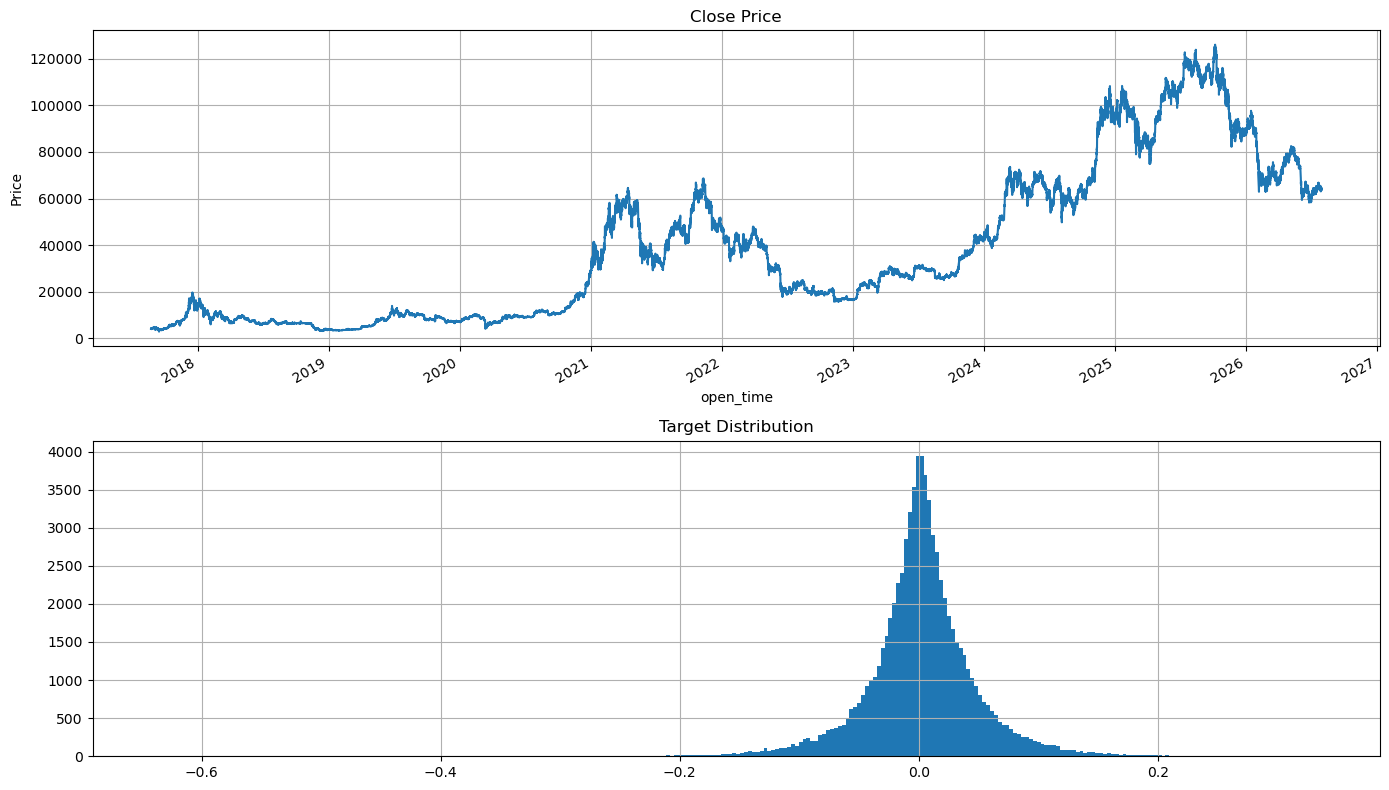

In [8]:
fig, ax = plt.subplots(2, 1, figsize=(14, 8), sharex=False)

df["close"].plot(ax=ax[0], title="Close Price", grid=True)
df[target_col].hist(ax=ax[1], bins=300, grid=True)

ax[0].set_ylabel("Price")
ax[1].set_title("Target Distribution")
plt.tight_layout()
plt.show()

# Neural Network Model

In [9]:
class NeuralNetworkModel:
    def __init__(
        self,
        n_features,
        hidden_size=16,
        lr=0.001,
        model_l2=0.0,
        seed=42
    ):
        self.lr = lr
        self.model_l2 = model_l2

        # Local random generator for reproducible initialization
        rng = np.random.default_rng(seed)

        self.W1 = (
            rng.standard_normal((n_features, hidden_size))
            * np.sqrt(2.0 / n_features)
        )
        self.b1 = np.zeros(hidden_size)

        self.W2 = (
            rng.standard_normal(hidden_size)
            * np.sqrt(1.0 / hidden_size)
        )
        self.b2 = 0.0

    def predict(self, x):
        x = np.asarray(x, dtype=float).reshape(-1)

        self.z1 = x @ self.W1 + self.b1
        self.a1 = np.maximum(0.0, self.z1)  # ReLU

        return float(self.a1 @ self.W2 + self.b2)

    def update(self, x, y):
        x = np.asarray(x, dtype=float).reshape(-1)
        y = float(y)

        # Forward pass
        pred = self.predict(x)
        err = pred - y

        # Backpropagation: gradients of 0.5 * (pred - y)^2
        dW2 = self.a1 * err + self.model_l2 * self.W2
        db2 = err

        da1 = self.W2 * err
        dz1 = da1 * (self.z1 > 0)

        dW1 = np.outer(x, dz1) + self.model_l2 * self.W1
        db1 = dz1

        # Gradient descent
        self.W2 -= self.lr * dW2
        self.b2 -= self.lr * db2

        self.W1 -= self.lr * dW1
        self.b1 -= self.lr * db1

        return err

# Regression Metrics

In [10]:
def regression_metrics(y_true, y_pred):
    y_true = np.asarray(y_true, dtype=float)
    y_pred = np.asarray(y_pred, dtype=float)

    mse = np.mean((y_true - y_pred) ** 2)
    mae = np.mean(np.abs(y_true - y_pred))

    if np.std(y_true) == 0 or np.std(y_pred) == 0:
        corr = np.nan
    else:
        corr = np.corrcoef(y_true, y_pred)[0, 1]

    direction_acc = np.mean(np.sign(y_true) == np.sign(y_pred))

    return {
        "mse": float(mse),
        "mae": float(mae),
        "corr": float(corr) if not np.isnan(corr) else np.nan,
        "direction_acc": float(direction_acc),
    }


def max_drawdown(equity_curve):
    eq = np.asarray(equity_curve, dtype=float)
    peaks = np.maximum.accumulate(eq)
    drawdowns = (eq - peaks) / peaks
    return float(drawdowns.min())


def sharpe_ratio(returns, bars_per_year=24*365):
    rets = np.asarray(returns, dtype=float)
    if len(rets) < 2 or np.std(rets) == 0:
        return np.nan
    return float(np.sqrt(bars_per_year) * rets.mean() / rets.std())

# Trading Rule

In [11]:
def prediction_to_position(pred, threshold, allow_shorts=True):
    threshold = abs(threshold)
    if pred > threshold:
        return 1
    elif allow_shorts and pred < -threshold:
        return -1
    else:
        return 0

# Walk-Forward Evaluation

In [12]:
def walk_forward_simulation(
    df,
    feature_cols,
    target_col,
    pnl_return_col,
    horizon=30,
    lr=0.01,
    model_l2=0.0001,
    threshold_multiplier=1.25,
    allow_shorts=True,
    initial_balance=10_000.0,
    hidden_size=16,
    scaler_rows=5000
):
    threshold = threshold_multiplier * ONE_WAY_COST

    X_raw = df[feature_cols].astype(float).to_numpy()
    y = df[target_col].astype(float).to_numpy()
    y_pnl = df[pnl_return_col].astype(float).to_numpy()

    if scaler_rows < 2 or scaler_rows >= len(df):
        raise ValueError("scaler_rows must be between 2 and len(df) - 1")

    # Fit using only the initial calibration rows; then freeze these values.
    feature_mean = X_raw[:scaler_rows].mean(axis=0)
    feature_std = X_raw[:scaler_rows].std(axis=0)

    # Avoid division by zero for constant features.
    feature_std[feature_std < 1e-12] = 1.0

    # Apply the same, frozen transform to all rows.
    X = (X_raw - feature_mean) / feature_std

    model = NeuralNetworkModel(
        n_features=len(feature_cols),
        hidden_size=hidden_size,
        lr=lr,
        model_l2=model_l2,
        seed=42
    )

    preds = []
    positions = []
    pnl_dollars = []
    pnl_pct = []
    equity_curve = [initial_balance]

    prev_position = 0
    pending_updates = deque()

    # No predictions or performance scoring during scaler calibration.
    for i in range(scaler_rows, len(df)):

        # Train only when the sample's target is known.
        while pending_updates and pending_updates[0][0] <= i:
            _, x_ready, y_ready = pending_updates.popleft()
            model.update(x_ready, y_ready)

        x_i = X[i]
        y_i = y[i]
        pnl_logret_i = y_pnl[i]

        pred = model.predict(x_i)
        pred = float(np.clip(pred, -0.2, 0.2))

        position = prediction_to_position(
            pred,
            threshold,
            allow_shorts=allow_shorts
        )

        simple_return_1 = np.exp(pnl_logret_i) - 1.0
        position_size = equity_curve[-1] * LEVERAGE * RISK_PER_TRADE
        turnover = abs(position - prev_position)

        costs = ONE_WAY_COST * turnover * position_size
        gross_pnl = position * simple_return_1 * position_size
        net_pnl = gross_pnl - costs

        new_equity = equity_curve[-1] + net_pnl

        preds.append(pred)
        positions.append(position)
        pnl_dollars.append(net_pnl)
        pnl_pct.append(
            net_pnl / equity_curve[-1] if equity_curve[-1] != 0 else 0.0
        )
        equity_curve.append(new_equity)

        # Store the already-scaled feature vector for its later online update.
        pending_updates.append((i + horizon, x_i.copy(), y_i))

        prev_position = position

    # Results and metrics cover only the post-calibration period.
    result = df.iloc[scaler_rows:].copy()
    result["prediction"] = preds
    result["position"] = positions
    result["strategy_pnl"] = pnl_dollars
    result["strategy_return"] = pnl_pct
    result["equity"] = equity_curve[1:]

    # Keep these so the same scaling can be applied in live inference.
    result.attrs["scaler_mean"] = feature_mean
    result.attrs["scaler_std"] = feature_std

    pred_metrics = regression_metrics(result[target_col], result["prediction"])

    prev_pos = result["position"].shift(1).fillna(0)
    trade_count = int((result["position"] != prev_pos).sum())
    long_count = int(((result["position"] == 1) & (prev_pos != 1)).sum())
    short_count = int(((result["position"] == -1) & (prev_pos != -1)).sum())
    flat_count = int(((result["position"] == 0) & (prev_pos != 0)).sum())

    trading_metrics = {
        "final_equity": float(result["equity"].iloc[-1]),
        "total_return": float(result["equity"].iloc[-1] / initial_balance - 1.0),
        "sharpe": sharpe_ratio(result["strategy_return"]),
        "max_drawdown": max_drawdown(result["equity"]),
        "trade_count": trade_count,
        "long_count": long_count,
        "short_count": short_count,
        "flat_count": flat_count,
        "avg_bar_return": float(result["strategy_return"].mean()),
    }

    return result, pred_metrics, trading_metrics

# Baseline Run

In [13]:
baseline_result, baseline_pred_metrics, baseline_trading_metrics = walk_forward_simulation(
    df=df,
    feature_cols=feature_cols,
    target_col=target_col,
    pnl_return_col=pnl_col,
    horizon=HORIZON,
    lr=LR,
    model_l2=MODEL_L2,
    threshold_multiplier=THRESHOLD_MULTIPLIER,
    allow_shorts=ALLOW_SHORTS,
    initial_balance=INITIAL_BALANCE,
    hidden_size=HIDDEN_SIZE,
    scaler_rows=SCALER_ROWS
)

print("Prediction Metrics")
print(pd.Series(baseline_pred_metrics))

print("\nTrading Metrics")
print(pd.Series(baseline_trading_metrics))

Prediction Metrics
mse              0.002360
mae              0.033046
corr             0.048643
direction_acc    0.519979
dtype: float64

Trading Metrics
final_equity      18195.150436
total_return          0.819515
sharpe                0.983108
max_drawdown         -0.076893
trade_count         413.000000
long_count          106.000000
short_count         109.000000
flat_count          198.000000
avg_bar_return        0.000008
dtype: float64


# Plot Equity Curve

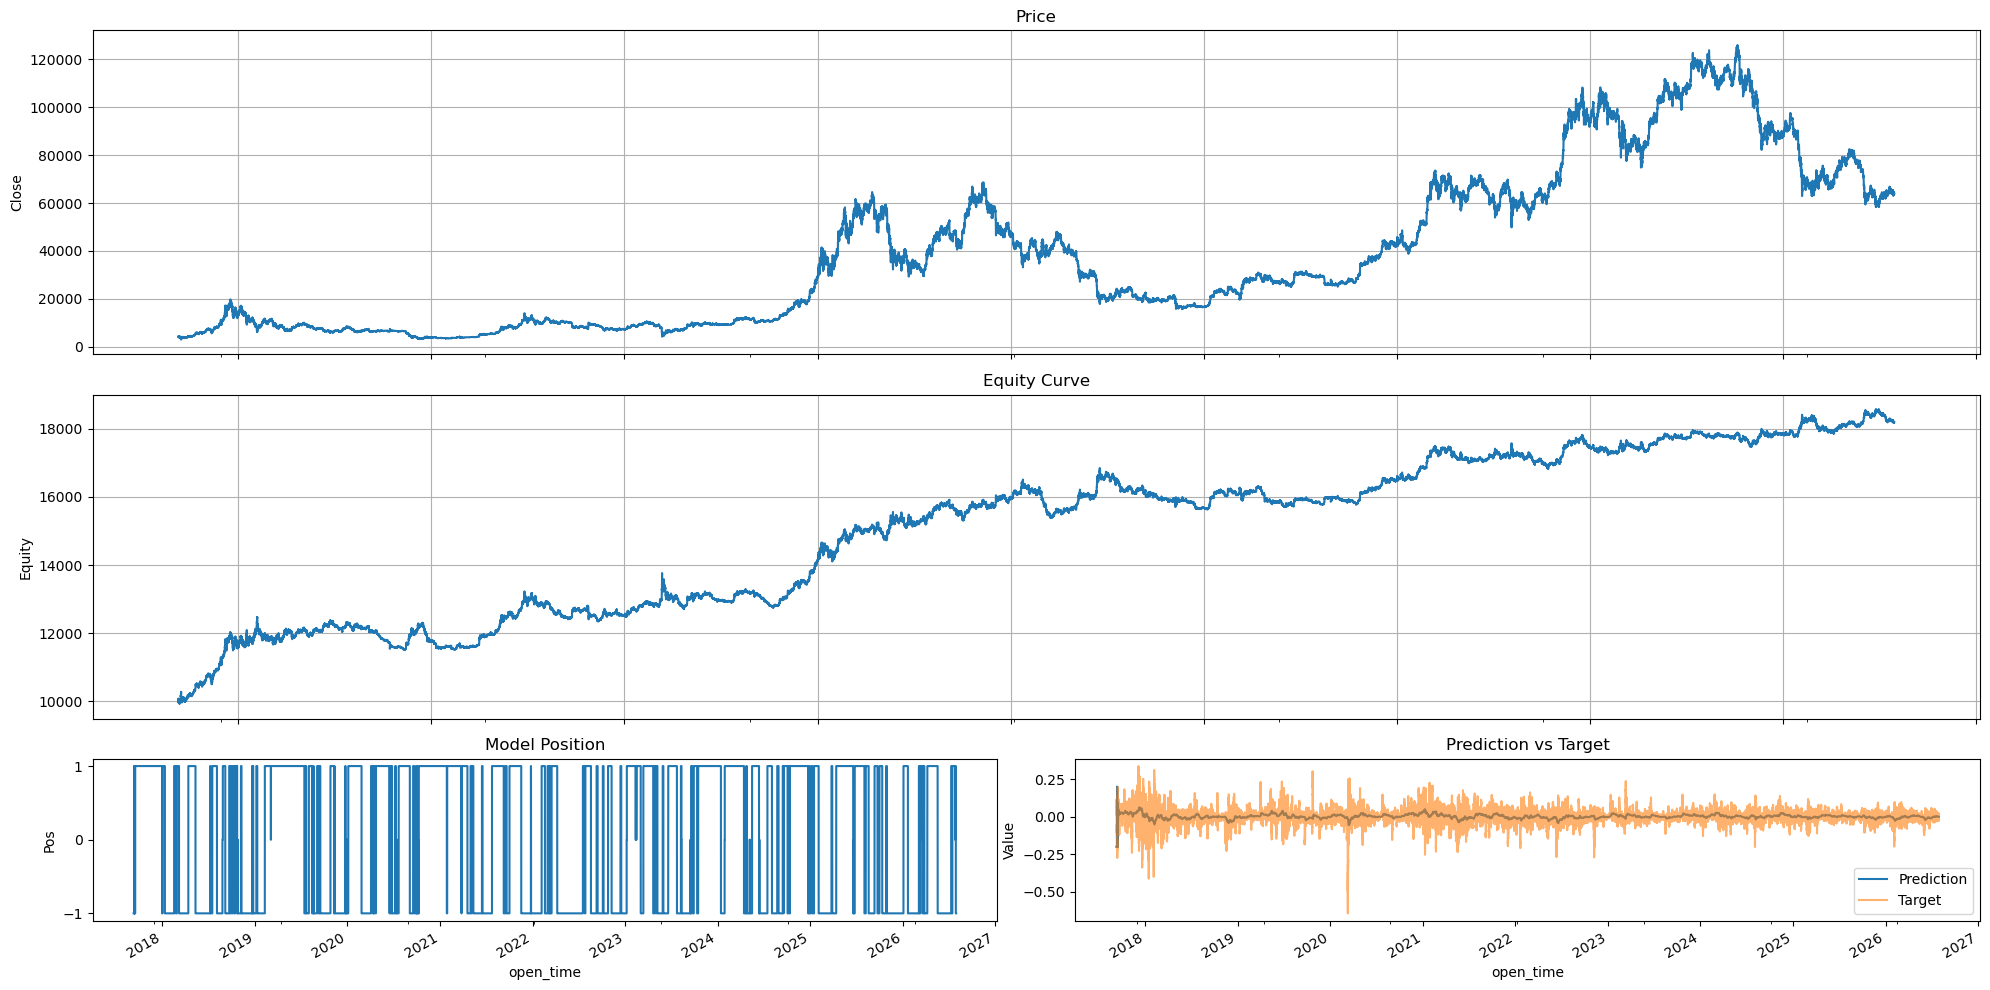

In [14]:
fig = plt.figure(figsize=(20, 10))
gs = fig.add_gridspec(3, 2, height_ratios=[2, 2, 1])

ax_price = fig.add_subplot(gs[0, :])
ax_equity = fig.add_subplot(gs[1, :], sharex=ax_price)
ax_pos = fig.add_subplot(gs[2, 0], sharex=ax_price)
ax_pred = fig.add_subplot(gs[2, 1], sharex=ax_price)

baseline_result["close"].plot(ax=ax_price, title="Price", grid=True)
baseline_result["equity"].plot(ax=ax_equity, title="Equity Curve", grid=True)
baseline_result["position"].plot(ax=ax_pos, title="Model Position", drawstyle="steps-post")

baseline_result["prediction"].plot(ax=ax_pred, label="Prediction", title="Prediction vs Target")
baseline_result[target_col].plot(ax=ax_pred, label="Target", alpha=0.6)

ax_price.set_ylabel("Close")
ax_equity.set_ylabel("Equity")
ax_pos.set_ylabel("Pos")
ax_pred.set_ylabel("Value")

ax_pos.set_yticks([-1, 0, 1])
ax_pred.legend()

plt.tight_layout()
plt.show()

# Baseline Feature Importance

In [15]:
X = df[feature_cols].astype(float).to_numpy()
y = df[target_col].astype(float).to_numpy()

importance_model = NeuralNetworkModel(
    n_features=len(feature_cols),
    hidden_size=16,
    lr=LR,
    model_l2=MODEL_L2
)

baseline_pred = np.array([
    importance_model.predict(row) for row in X
])

baseline_mse = np.mean((baseline_pred - y) ** 2)

rng = np.random.default_rng(42)
importance_scores = []

for j, feature in enumerate(feature_cols):
    X_permuted = X.copy()
    X_permuted[:, j] = rng.permutation(X_permuted[:, j])

    permuted_pred = np.array([
        importance_model.predict(row) for row in X_permuted
    ])

    permuted_mse = np.mean((permuted_pred - y) ** 2)

    importance_scores.append({
        "feature": feature,
        "importance": permuted_mse - baseline_mse,
    })

feature_importance = (
    pd.DataFrame(importance_scores)
    .sort_values("importance", ascending=False)
    .reset_index(drop=True)
)

display(feature_importance)

,feature,importance
0,ret_72,-0.000362
1,taker_buy_fraction,-0.000487
2,trades_log,-0.000780
3,ret_168,-0.001050


# Hyperparameter Study

In [16]:
hyperparameter_study = []

for horizon, threshold_multiplier, lr, model_l2, hidden_size in product(
    HORIZON_GRID,
    THRESHOLD_MULTIPLIER_GRID,
    LR_GRID,
    MODEL_L2_GRID,
    HIDDEN_SIZE_GRID
):
    tmp_df, tmp_features, tmp_target, pnl_col = build_features(
        raw_df,
        horizon
    )

    _, pred_m, trade_m = walk_forward_simulation(
        tmp_df,
        tmp_features,
        tmp_target,
        pnl_col,
        horizon,
        lr,
        model_l2,
        threshold_multiplier,
        ALLOW_SHORTS,
        INITIAL_BALANCE,
        hidden_size,
        SCALER_ROWS
    )

    row = {
        "HORIZON": horizon,
        "THRESHOLD_MULTIPLIER": threshold_multiplier,
        "LR": lr,
        "MODEL_L2": model_l2,
        "HIDDEN_SIZE": hidden_size,
        **pred_m,
        **trade_m,
    }
    hyperparameter_study.append(row)

hyperparameter_study_df = pd.DataFrame(hyperparameter_study).sort_values(
    ["sharpe", "total_return", "max_drawdown", "corr"],
    ascending=[False, False, True, False]
)

best_hyper_param = hyperparameter_study_df.iloc[0].to_dict()
hyperparameter_study_df.head(10)

,HORIZON,THRESHOLD_MULTIPLIER,LR,MODEL_L2,HIDDEN_SIZE,mse,mae,corr,direction_acc,final_equity,total_return,sharpe,max_drawdown,trade_count,long_count,short_count,flat_count,avg_bar_return
121,44,0.088,0.002675,3.75,20,0.002360,0.033046,0.048643,0.519979,18195.150436,0.819515,0.983108,-0.076893,413,106,109,198,0.000008
118,44,0.088,0.002675,3.50,20,0.002361,0.033050,0.048542,0.519966,18171.461599,0.817146,0.981047,-0.076893,415,107,110,198,0.000008
94,44,0.066,0.002675,3.75,20,0.002360,0.033046,0.048643,0.519979,18117.525511,0.811753,0.975987,-0.077469,412,106,110,196,0.000008
124,44,0.088,0.002675,4.00,20,0.002358,0.033041,0.048850,0.519992,18104.252701,0.810425,0.975164,-0.076893,413,106,109,198,0.000008
190,45,0.088,0.002650,3.50,20,0.002414,0.033482,0.050502,0.519253,18090.220971,0.809022,0.974386,-0.080417,408,104,109,195,0.000008
91,44,0.066,0.002675,3.50,20,0.002361,0.033050,0.048542,0.519966,18093.937735,0.809394,0.973928,-0.077469,414,107,111,196,0.000008
97,44,0.066,0.002675,4.00,20,0.002358,0.033041,0.048850,0.519992,18027.015567,0.802702,0.968047,-0.077469,412,106,110,196,0.000008
163,45,0.066,0.002650,3.50,20,0.002414,0.033482,0.050502,0.519253,18019.436327,0.801944,0.967670,-0.079089,399,105,106,188,0.000008
196,45,0.088,0.002650,4.00,20,0.002411,0.033474,0.050703,0.519265,17999.847433,0.799985,0.966438,-0.080417,408,104,109,195,0.000008
193,45,0.088,0.002650,3.75,20,0.002412,0.033478,0.050544,0.519265,17999.847433,0.799985,0.966438,-0.080417,408,104,109,195,0.000008


# Final Test

In [17]:
df_final, feature_cols_final, target_col_final, pnl_col = build_features(
    raw_df,
    int(best_hyper_param["HORIZON"])
)

final_result, final_pred_metrics, final_trading_metrics = walk_forward_simulation(
    df=df_final,
    feature_cols=feature_cols_final,
    target_col=target_col_final,
    pnl_return_col=pnl_col,
    horizon=best_hyper_param["HORIZON"],
    lr=best_hyper_param["LR"],
    model_l2=best_hyper_param["MODEL_L2"],
    threshold_multiplier=best_hyper_param["THRESHOLD_MULTIPLIER"],
    allow_shorts=ALLOW_SHORTS,
    initial_balance=INITIAL_BALANCE,
    hidden_size=int(best_hyper_param["HIDDEN_SIZE"]),
    scaler_rows=SCALER_ROWS
)

print("Final Prediction Metrics")
print(pd.Series(final_pred_metrics))

print("\nFinal Trading Metrics")
print(pd.Series(final_trading_metrics))

Final Prediction Metrics
mse              0.002360
mae              0.033046
corr             0.048643
direction_acc    0.519979
dtype: float64

Final Trading Metrics
final_equity      18195.150436
total_return          0.819515
sharpe                0.983108
max_drawdown         -0.076893
trade_count         413.000000
long_count          106.000000
short_count         109.000000
flat_count          198.000000
avg_bar_return        0.000008
dtype: float64


# Final Equity Plot

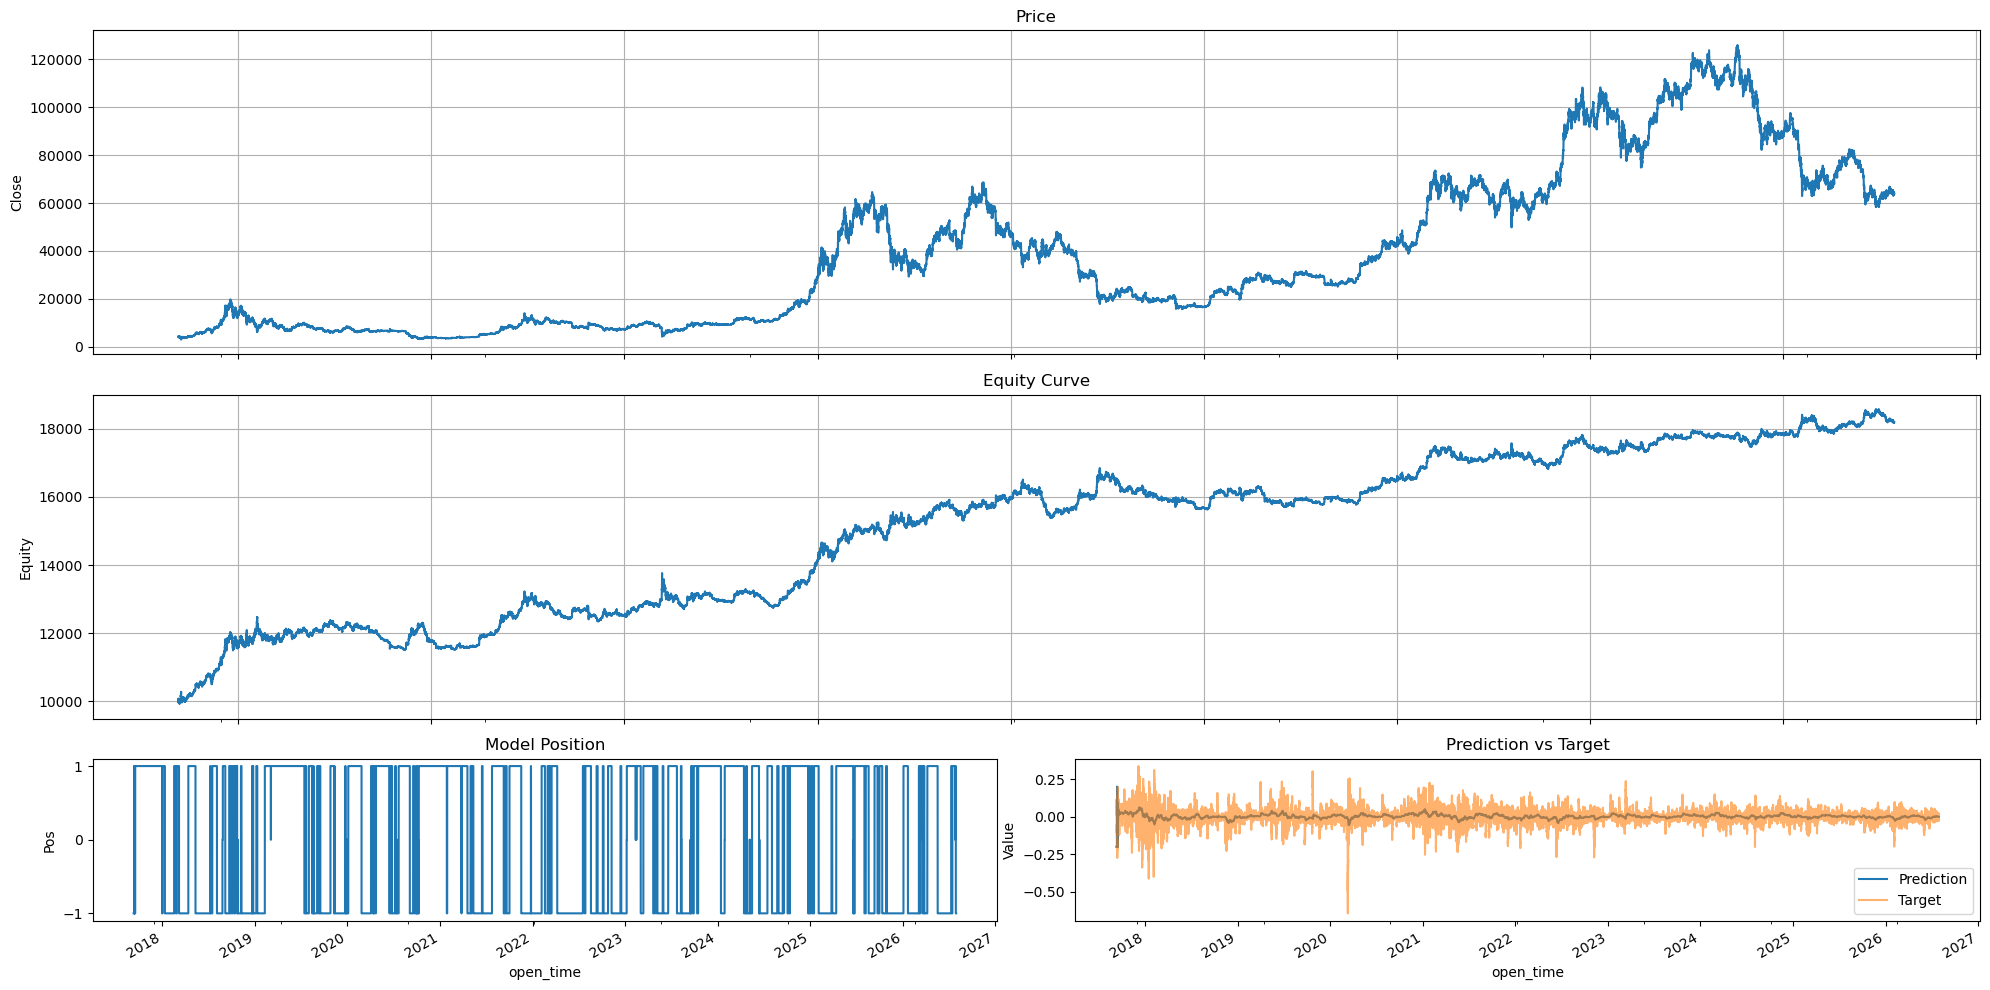

In [18]:
fig = plt.figure(figsize=(20, 10))
gs = fig.add_gridspec(3, 2, height_ratios=[2, 2, 1])

ax_price = fig.add_subplot(gs[0, :])
ax_equity = fig.add_subplot(gs[1, :], sharex=ax_price)
ax_pos = fig.add_subplot(gs[2, 0], sharex=ax_price)
ax_pred = fig.add_subplot(gs[2, 1], sharex=ax_price)

final_result["close"].plot(ax=ax_price, title="Price", grid=True)
final_result["equity"].plot(ax=ax_equity, title="Equity Curve", grid=True)
final_result["position"].plot(ax=ax_pos, title="Model Position", drawstyle="steps-post")

final_result["prediction"].plot(ax=ax_pred, label="Prediction", title="Prediction vs Target")
final_result[target_col].plot(ax=ax_pred, label="Target", alpha=0.6)

ax_price.set_ylabel("Close")
ax_equity.set_ylabel("Equity")
ax_pos.set_ylabel("Pos")
ax_pred.set_ylabel("Value")

ax_pos.set_yticks([-1, 0, 1])
ax_pred.legend()

plt.tight_layout()
plt.show()

# Research Summary Table

In [19]:
summary = pd.DataFrame({
    "baseline_pred": pd.Series(baseline_pred_metrics),
    "final_pred": pd.Series(final_pred_metrics),
})

summary

,baseline_pred,final_pred
mse,0.002360,0.002360
mae,0.033046,0.033046
corr,0.048643,0.048643
direction_acc,0.519979,0.519979


# Trading Summary Table

In [20]:
trading_summary = pd.DataFrame({
    "baseline_trading": pd.Series(baseline_trading_metrics),
    "final_trading": pd.Series(final_trading_metrics),
})

trading_summary

,baseline_trading,final_trading
final_equity,18195.150436,18195.150436
total_return,0.819515,0.819515
sharpe,0.983108,0.983108
max_drawdown,-0.076893,-0.076893
trade_count,413.000000,413.000000
long_count,106.000000,106.000000
short_count,109.000000,109.000000
flat_count,198.000000,198.000000
avg_bar_return,0.000008,0.000008


# Final Feature Importance

In [21]:
X_final = df_final[feature_cols_final].astype(float).to_numpy()
y_final = df_final[target_col_final].astype(float).to_numpy()

importance_model = NeuralNetworkModel(
    n_features=len(feature_cols_final),
    hidden_size=int(best_hyper_param["HIDDEN_SIZE"]),
    lr=float(best_hyper_param["LR"]),
    model_l2=float(best_hyper_param["MODEL_L2"])
)

final_pred = np.array([
    importance_model.predict(row) for row in X_final
])

final_mse = np.mean((final_pred - y_final) ** 2)

rng = np.random.default_rng(42)
importance_scores = []

for j, feature in enumerate(feature_cols):
    X_permuted = X_final.copy()
    X_permuted[:, j] = rng.permutation(X_permuted[:, j])

    permuted_pred = np.array([
        importance_model.predict(row) for row in X_permuted
    ])

    permuted_mse = np.mean((permuted_pred - y_final) ** 2)

    importance_scores.append({
        "feature": feature,
        "importance": permuted_mse - final_mse,
    })

feature_importance = (
    pd.DataFrame(importance_scores)
    .sort_values("importance", ascending=False)
    .reset_index(drop=True)
)

display(feature_importance)

,feature,importance
0,taker_buy_fraction,0.000374
1,trades_log,-0.001843
2,ret_72,-0.002997
3,ret_168,-0.003753
